# Diabetic Retinopathy using CNN

## 1. Import Libraries

In [ ]:
import tensorflow as tf 
from tensorflow.keras import layers, models 
import matplotlib.pyplot as plt 
import numpy as np 
import pickle 
from sklearn.model_selection import train_test_split

I0000 00:00:1784391948.084470    7779 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1784391950.097086    7779 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1784392027.952005    7779 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Load data

In [ ]:
with open("../../../data/processed/aptos/sample_200_gaus/sample_dataset.pkl", "rb") as file: 
    data = pickle.load(file)

In [ ]:
data['data'].shape

(993, 300, 300, 3)

## 3. Data Preprocessing 

In [ ]:
X = data['data']
y = data['labels']
class_names = data['class_names']

In [ ]:
class_names

['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferate_DR']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(x_train.shape)
print(x_test.shape) 

(794, 300, 300, 3)
(199, 300, 300, 3)


In [ ]:
num_classes = 5 
x_train, x_test = x_train/255.0, x_test/255.0
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test = tf.keras.utils.to_categorical(y_test, num_classes)

## Xem hình ảnh

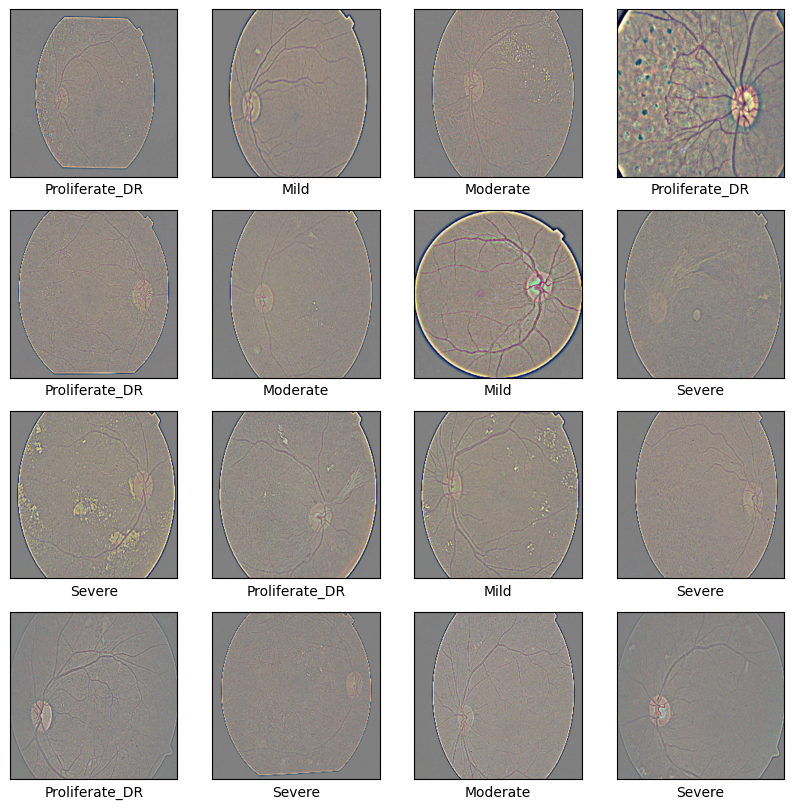

In [ ]:
plt.figure(figsize=(10,10))
for i in range(16): 
    plt.subplot(4,4,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[np.argmax(y_train[i])])
plt.show()

## 3. Building the CNN Model 

In [ ]:
model = models.Sequential([
    
    # Block 1
    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(300, 300, 3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),  # → 150x150

    # Block 2
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),  # → 75x75

    # Block 3
    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),  # → 37x37

    # Block 4
    layers.Conv2D(256, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),  # → 18x18

    # Block 5
    layers.Conv2D(256, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),  # → 9x9

    layers.Flatten(),
    layers.Dropout(0.5),

    layers.Dense(512, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1784392086.955793    7779 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 300, 300, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 300, 300, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150, 150, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 75, 75, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 37, 37, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 18, 18, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 18, 18, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    10,617,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,601,349 (44.26 MB)

 Trainable params: 11,599,877 (44.25 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [ ]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
history = model.fit(x_train, y_train, epochs=20, batch_size=4, validation_split=0.2, verbose=2)

Epoch 1/20


I0000 00:00:1784392092.014077    9104 service.cc:153] XLA service 0x7e899403c0a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1784392092.014106    9104 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1784392092.146936    9104 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1784392092.646321    9104 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1784392092.756885    9104 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5012__.91
W0000 00:00:1784392103.568631    9104 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.05GiB (rounded to 1125777920)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve 

159/159 - 225s - 1s/step - accuracy: 0.3008 - loss: 9.5320 - val_accuracy: 0.2075 - val_loss: 7.0663
Epoch 2/20
159/159 - 6s - 37ms/step - accuracy: 0.3748 - loss: 1.5246 - val_accuracy: 0.2075 - val_loss: 7.5515
Epoch 3/20
159/159 - 6s - 37ms/step - accuracy: 0.4031 - loss: 1.3690 - val_accuracy: 0.2516 - val_loss: 2.4615
Epoch 4/20
159/159 - 6s - 36ms/step - accuracy: 0.4110 - loss: 1.3489 - val_accuracy: 0.3522 - val_loss: 1.3736
Epoch 5/20
159/159 - 6s - 37ms/step - accuracy: 0.4299 - loss: 1.3458 - val_accuracy: 0.3711 - val_loss: 4.9534
Epoch 6/20
159/159 - 13s - 83ms/step - accuracy: 0.3969 - loss: 1.4263 - val_accuracy: 0.5535 - val_loss: 1.2618
Epoch 7/20
159/159 - 6s - 37ms/step - accuracy: 0.4268 - loss: 1.3374 - val_accuracy: 0.4340 - val_loss: 1.5338
Epoch 8/20
159/159 - 10s - 66ms/step - accuracy: 0.4362 - loss: 1.2978 - val_accuracy: 0.3774 - val_loss: 1.6122
Epoch 9/20
159/159 - 6s - 37ms/step - accuracy: 0.3953 - loss: 1.3576 - val_accuracy: 0.4088 - val_loss: 1.4848
E

## 4. Result

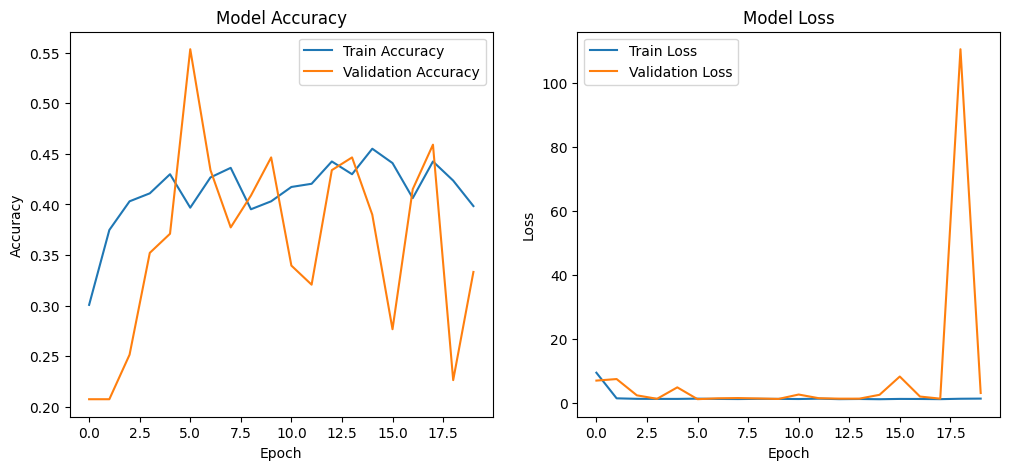

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()